In [26]:
# ==========================================
# PROJECT 25: WATER USAGE & CONSERVATION
# ==========================================

# Import required libraries
import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv("data/25_water_consumption.csv")

In [27]:
# Display first five records
print("\n========== FIRST FIVE RECORDS ==========")
print(df.head())

# Display dataset dimensions
print("\n========== DATASET DIMENSIONS ==========")
print("Rows and Columns:", df.shape)

# Display column names
print("\n========== COLUMN NAMES ==========")
print(df.columns.tolist())

# Display data types
print("\n========== DATA TYPES ==========")
print(df.dtypes)

# Display dataset information
print("\n========== DATASET INFORMATION ==========")
df.info()

# Display missing values
print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())


========== FIRST FIVE RECORDS ==========
  Meter_Record_ID Household_ID Reading_Date Household_Type Building_Type  \
0        WM000000      HH00329   16-11-2025    Independent     Mixed Use   
1        WM000001      HH00194   14-08-2025         Hostel     Mixed Use   
2        WM000002      HH00314   30-06-2026    Independent     Mixed Use   
3        WM000003      HH00229   10-01-2026         Hostel     Mixed Use   
4        WM000004      HH00287   07-03-2025      Apartment   Residential   

     Zone  Water_Usage_Liters  
0  Zone A              2754.5  
1  Zone C              6304.6  
2  Zone E              7307.3  
3  Zone E             11604.3  
4  Zone C              5996.4  

========== DATASET DIMENSIONS ==========
Rows and Columns: (862, 7)

========== COLUMN NAMES ==========
['Meter_Record_ID', 'Household_ID', 'Reading_Date', 'Household_Type', 'Building_Type', 'Zone', 'Water_Usage_Liters']

========== DATA TYPES ==========
Meter_Record_ID           str
Household_ID           

In [28]:
# ==========================================
# TASK 2: IDENTIFY DUPLICATES
# ==========================================

print("\n========== DUPLICATE RECORDS ==========")

# Count duplicate meter record IDs
duplicate_count = df["Meter_Record_ID"].duplicated().sum()

print("Duplicate Meter Record IDs:", duplicate_count)

# Display duplicate records
duplicates = df[df["Meter_Record_ID"].duplicated(keep=False)]

print("\nDuplicate Records:")
print(duplicates)


========== DUPLICATE RECORDS ==========
Duplicate Meter Record IDs: 12

Duplicate Records:
    Meter_Record_ID Household_ID Reading_Date Household_Type Building_Type  \
39         WM000039      HH00181   11-08-2026         Hostel    Commercial   
66         WM000066      HH00386   25-12-2025      Apartment     Mixed Use   
110        WM000110      HH00088   31-12-2025      Apartment     Mixed Use   
260        WM000260      HH00354   05-09-2026    Independent   Residential   
357        WM000357      HH00417   14-10-2025          Villa   Residential   
447        WM000447      HH00430   16-10-2025          Villa   Residential   
467        WM000467      HH00125   03-06-2026      Apartment   Residential   
512        WM000512      HH00358   10-02-2026         Hostel   Residential   
684        WM000684      HH00013   06-09-2026    Independent     Mixed Use   
705        WM000705      HH00147   13-06-2025         Hostel    Commercial   
756        WM000756      HH00236   30-03-2026    I

In [29]:
# ==========================================
# TASK 3: HANDLE MISSING VALUES
# ==========================================

print("\n========== HANDLING MISSING VALUES ==========")

# Calculate median water usage
median_usage = df["Water_Usage_Liters"].median()

print("Median Water Usage:", median_usage)

# Fill missing values with median
df["Water_Usage_Liters"] = df["Water_Usage_Liters"].fillna(median_usage)

# Check missing values after filling
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())


========== HANDLING MISSING VALUES ==========
Median Water Usage: 6402.4

Missing Values After Cleaning:
Meter_Record_ID       0
Household_ID          0
Reading_Date          0
Household_Type        0
Building_Type         0
Zone                  0
Water_Usage_Liters    0
dtype: int64


In [30]:
%pip install pandas numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
# ==========================================
# TASK 4: DATE CONVERSION
# ==========================================

print("\n========== DATE CONVERSION ==========")

# Convert Reading_Date into datetime format
df["Reading_Date"] = pd.to_datetime(df["Reading_Date"], errors="coerce")

# Extract month name
df["Month"] = df["Reading_Date"].dt.month_name()

# Extract weekday name
df["Weekday"] = df["Reading_Date"].dt.day_name()

# Display selected columns
print("\nDate, Month and Weekday:")
print(df[["Reading_Date", "Month", "Weekday"]].head(10))

# Check the data type
print("\nReading_Date Data Type:")
print(df["Reading_Date"].dtype)

# Check invalid dates
print("\nInvalid Dates:", df["Reading_Date"].isnull().sum())


========== DATE CONVERSION ==========

Date, Month and Weekday:
  Reading_Date     Month    Weekday
0   2025-11-16  November     Sunday
1   2025-08-14    August   Thursday
2   2026-06-30      June    Tuesday
3   2026-01-10   January   Saturday
4   2025-03-07     March     Friday
5   2025-08-01    August     Friday
6   2025-12-24  December  Wednesday
7   2025-08-02    August   Saturday
8   2025-07-28      July     Monday
9   2026-10-24   October   Saturday

Reading_Date Data Type:
datetime64[us]

Invalid Dates: 0


C:\Users\hp\AppData\Local\Temp\ipykernel_10084\3101595172.py:8: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Reading_Date"] = pd.to_datetime(df["Reading_Date"], errors="coerce")


In [32]:
# ==========================================
# TASK 5: WATER CONSUMPTION CALCULATIONS
# ==========================================

print("\n========== WATER CONSUMPTION ANALYSIS ==========")

# Calculate total water consumption
total_consumption = df["Water_Usage_Liters"].sum()

print("Total Water Consumption:", total_consumption, "Litres")

# Calculate total consumption for each household
household_consumption = df.groupby("Household_ID")["Water_Usage_Liters"].sum()

print("\n========== HOUSEHOLD-WISE CONSUMPTION ==========")
print(household_consumption)

# Calculate average consumption per household
average_consumption = household_consumption.mean()

print("\nAverage Consumption Per Household:",
      round(average_consumption, 2), "Litres")

# Count unique households
total_households = df["Household_ID"].nunique()

print("Total Number of Households:", total_households)


========== WATER CONSUMPTION ANALYSIS ==========
Total Water Consumption: 5419898.9 Litres

========== HOUSEHOLD-WISE CONSUMPTION ==========
Household_ID
HH00001     1594.4
HH00004    10572.0
HH00005    22680.0
HH00006    14005.5
HH00007     5859.2
            ...   
HH00444     4190.2
HH00445     7659.9
HH00447    14531.7
HH00448    28562.1
HH00449    32426.1
Name: Water_Usage_Liters, Length: 370, dtype: float64

Average Consumption Per Household: 14648.38 Litres
Total Number of Households: 370


In [33]:
# ==========================================
# TASK 6: MONTH-TO-MONTH CONSUMPTION CHANGE
# ==========================================

print("\n========== MONTHLY WATER CONSUMPTION ==========")

# Extract year and month from Reading_Date
df["Year_Month"] = df["Reading_Date"].dt.to_period("M")

# Calculate monthly consumption for each household
monthly_consumption = df.groupby(
    ["Household_ID", "Year_Month"]
)["Water_Usage_Liters"].sum().reset_index()

# Rename the consumption column
monthly_consumption.rename(
    columns={"Water_Usage_Liters": "Monthly_Consumption"},
    inplace=True
)

# Sort records by household and month
monthly_consumption = monthly_consumption.sort_values(
    ["Household_ID", "Year_Month"]
)

# Calculate percentage change from previous month
monthly_consumption["Monthly_Change_Percent"] = (
    monthly_consumption.groupby("Household_ID")[
        "Monthly_Consumption"
    ].pct_change(fill_method=None) * 100
)

# Display monthly consumption and changes
print("\n========== MONTH-TO-MONTH CHANGE ==========")
print(monthly_consumption.head(20).to_string(index=False))

# Display average monthly consumption change
average_change = monthly_consumption[
    "Monthly_Change_Percent"
].mean()

print("\nAverage Monthly Change:",
      round(average_change, 2), "%")


========== MONTHLY WATER CONSUMPTION ==========

========== MONTH-TO-MONTH CHANGE ==========
Household_ID Year_Month  Monthly_Consumption  Monthly_Change_Percent
     HH00001    2026-07               1594.4                     NaN
     HH00004    2025-08               2266.9                     NaN
     HH00004    2025-10               8305.1              266.363757
     HH00005    2025-03              11789.4                     NaN
     HH00005    2026-09              10890.6               -7.623798
     HH00006    2025-06              10188.1                     NaN
     HH00006    2025-10               3817.4              -62.530796
     HH00007    2026-05               3392.9                     NaN
     HH00007    2026-10               2466.3              -27.309971
     HH00008    2025-09               9457.4                     NaN
     HH00009    2026-08               4827.1                     NaN
     HH00011    2025-03               6563.6                     NaN
     HH00

C:\Users\hp\AppData\Local\Temp\ipykernel_10084\3658049084.py:16: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  monthly_consumption.rename(


In [34]:
# ==========================================
# TASK 7: RANK HOUSEHOLD TYPES
# ==========================================

print("\n========== HOUSEHOLD TYPE RANKING ==========")

# Calculate total water consumption by household type
type_consumption = df.groupby(
    "Household_Type"
)["Water_Usage_Liters"].sum().reset_index()

# Rename the consumption column
type_consumption.rename(
    columns={"Water_Usage_Liters": "Total_Consumption"},
    inplace=True
)

# Sort from highest to lowest consumption
type_consumption = type_consumption.sort_values(
    by="Total_Consumption",
    ascending=False
)

# Assign ranks
type_consumption["Rank"] = type_consumption[
    "Total_Consumption"
].rank(method="min", ascending=False).astype(int)

# Display ranking
type_consumption = type_consumption[
    ["Rank", "Household_Type", "Total_Consumption"]
]

print(type_consumption.to_string(index=False))


========== HOUSEHOLD TYPE RANKING ==========
 Rank Household_Type  Total_Consumption
    1          Villa          1382561.8
    2    Independent          1371226.4
    3         Hostel          1344052.9
    4      Apartment          1322057.8


C:\Users\hp\AppData\Local\Temp\ipykernel_10084\2177554971.py:13: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  type_consumption.rename(


In [35]:
# TASK 8: BUILDING TYPE AND ZONE ANALYSIS
# ==========================================

print("\n========== BUILDING TYPE ANALYSIS ==========")

# Calculate average consumption by building type
building_analysis = df.groupby(
    "Building_Type"
)["Water_Usage_Liters"].mean().reset_index()

# Rename the column
building_analysis.rename(
    columns={"Water_Usage_Liters": "Average_Consumption"},
    inplace=True
)

# Sort by average consumption
building_analysis = building_analysis.sort_values(
    by="Average_Consumption",
    ascending=False
)

print(building_analysis.to_string(index=False))


print("\n========== ZONE-WISE ANALYSIS ==========")

# Calculate average consumption by zone
zone_analysis = df.groupby(
    "Zone"
)["Water_Usage_Liters"].mean().reset_index()

# Rename the column
zone_analysis.rename(
    columns={"Water_Usage_Liters": "Average_Consumption"},
    inplace=True
)

# Sort by average consumption
zone_analysis = zone_analysis.sort_values(
    by="Average_Consumption",
    ascending=False
)

print(zone_analysis.to_string(index=False))


========== BUILDING TYPE ANALYSIS ==========
Building_Type  Average_Consumption
   Commercial          6540.536905
  Residential          6258.908889
    Mixed Use          6102.126441

========== ZONE-WISE ANALYSIS ==========
  Zone  Average_Consumption
Zone B          6797.509036
Zone A          6342.005161
Zone E          6302.511667
Zone D          6206.318935
Zone C          5860.320833


C:\Users\hp\AppData\Local\Temp\ipykernel_10084\1824468321.py:12: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  building_analysis.rename(
C:\Users\hp\AppData\Local\Temp\ipykernel_10084\1824468321.py:34: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  zone_analysis.rename(


In [36]:
# ==========================================
# TASK 9: IDENTIFY HIGH WATER CONSUMPTION
# ==========================================

print("\n========== HIGH WATER CONSUMPTION ANALYSIS ==========")

# Calculate average water usage per household
household_average = df.groupby(
    "Household_ID"
)["Water_Usage_Liters"].mean().reset_index()

# Rename the column
household_average.rename(
    columns={"Water_Usage_Liters": "Average_Usage"},
    inplace=True
)

# Calculate the 75th percentile threshold
threshold = household_average["Average_Usage"].quantile(0.75)

print("75th Percentile Threshold:", round(threshold, 2), "Litres")

# Identify households above the threshold
high_consumption = household_average[
    household_average["Average_Usage"] > threshold
]

# Sort households from highest to lowest usage
high_consumption = high_consumption.sort_values(
    by="Average_Usage",
    ascending=False
)

# Display high consumption households
print("\n========== HIGH CONSUMPTION HOUSEHOLDS ==========")
print(high_consumption.to_string(index=False))

# Display the number of high consumption households
print("\nNumber of High Consumption Households:",
      len(high_consumption))


========== HIGH WATER CONSUMPTION ANALYSIS ==========
75th Percentile Threshold: 7913.38 Litres

========== HIGH CONSUMPTION HOUSEHOLDS ==========
Household_ID  Average_Usage
     HH00034   11996.000000
     HH00413   11990.400000
     HH00135   11842.700000
     HH00014   11818.450000
     HH00396   11780.000000
     HH00420   11543.300000
     HH00005   11340.000000
     HH00271   11257.100000
     HH00369   11172.800000
     HH00154   11120.800000
     HH00382   10970.900000
     HH00022   10863.050000
     HH00363   10833.600000
     HH00236   10740.225000
     HH00149   10487.400000
     HH00430   10384.400000
     HH00045   10369.700000
     HH00366   10346.900000
     HH00231   10224.100000
     HH00266   10132.700000
     HH00441   10091.700000
     HH00302    9939.100000
     HH00259    9901.900000
     HH00295    9848.750000
     HH00145    9818.400000
     HH00387    9818.000000
     HH00241    9805.700000
     HH00028    9731.250000
     HH00016    9716.700000
     HH00204

C:\Users\hp\AppData\Local\Temp\ipykernel_10084\4099539116.py:13: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  household_average.rename(


In [37]:
# ==========================================
# TASK 10: ZONE-WISE HOUSEHOLD TYPE ANALYSIS
# ==========================================

print("\n========== ZONE-WISE HOUSEHOLD ANALYSIS ==========")

# Calculate total water usage by zone and household type
zone_household_analysis = df.pivot_table(
    index="Zone",
    columns="Household_Type",
    values="Water_Usage_Liters",
    aggfunc="sum",
    fill_value=0
)

# Display the analysis
print(zone_household_analysis)

# Calculate total consumption in each zone
print("\n========== TOTAL CONSUMPTION BY ZONE ==========")

zone_totals = df.groupby("Zone")[
    "Water_Usage_Liters"
].sum().sort_values(ascending=False)

print(zone_totals)

# Identify the zone with the highest consumption
highest_zone = zone_totals.idxmax()

print("\nZone with Highest Water Consumption:", highest_zone)
print("Highest Zone Consumption:", round(zone_totals.max(), 2), "Litres")


========== ZONE-WISE HOUSEHOLD ANALYSIS ==========
Household_Type  Apartment    Hostel  Independent     Villa
Zone                                                      
Zone A           223551.0  260250.3     236918.5  262291.0
Zone B           266377.1  205062.0     351087.7  305859.7
Zone C           326768.4  274085.2     258119.1  266208.9
Zone D           244194.3  287273.1     297844.4  219556.1
Zone E           261167.0  317382.3     227256.7  328646.1

========== TOTAL CONSUMPTION BY ZONE ==========
Zone
Zone E    1134452.1
Zone B    1128386.5
Zone C    1125181.6
Zone D    1048867.9
Zone A     983010.8
Name: Water_Usage_Liters, dtype: float64

Zone with Highest Water Consumption: Zone E
Highest Zone Consumption: 1134452.1 Litres


In [38]:
# ==========================================
# TASK 11: MONTHLY WATER CONSUMPTION ANALYSIS
# ==========================================

print("\n========== MONTHLY CONSUMPTION ANALYSIS ==========")

# Group water consumption by month
monthly_totals = df.groupby(
    "Month"
)["Water_Usage_Liters"].sum()

# Arrange months in calendar order
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_totals = monthly_totals.reindex(
    month_order
).dropna()

# Display monthly consumption
print(monthly_totals)

# Find the month with the highest consumption
highest_month = monthly_totals.idxmax()
highest_month_usage = monthly_totals.max()

print("\nMonth with Highest Consumption:", highest_month)
print("Highest Monthly Consumption:",
      round(highest_month_usage, 2), "Litres")

# Find the month with the lowest consumption
lowest_month = monthly_totals.idxmin()

print("Month with Lowest Consumption:", lowest_month)
print("Lowest Monthly Consumption:",
      round(monthly_totals.min(), 2), "Litres")


========== MONTHLY CONSUMPTION ANALYSIS ==========
Month
January      530184.0
February     509821.9
March        616311.2
April        559125.4
May          415286.2
June         523991.5
July         390227.4
August       413827.7
September    496413.3
October      493051.8
November     231502.9
December     240155.6
Name: Water_Usage_Liters, dtype: float64

Month with Highest Consumption: March
Highest Monthly Consumption: 616311.2 Litres
Month with Lowest Consumption: November
Lowest Monthly Consumption: 231502.9 Litres


In [39]:
# ==========================================
# TASK 12: WATER CONSUMPTION SUMMARY REPORT
# ==========================================

print("\n========== WATER CONSUMPTION SUMMARY REPORT ==========")

# Calculate important statistics
total_records = len(df)
total_households = df["Household_ID"].nunique()
total_usage = df["Water_Usage_Liters"].sum()
average_usage = df["Water_Usage_Liters"].mean()
maximum_usage = df["Water_Usage_Liters"].max()
minimum_usage = df["Water_Usage_Liters"].min()

# Display summary report
print("Total Meter Records:", total_records)
print("Total Households:", total_households)
print("Total Water Consumption:", round(total_usage, 2), "Litres")
print("Average Water Usage:", round(average_usage, 2), "Litres")
print("Maximum Water Usage:", maximum_usage, "Litres")
print("Minimum Water Usage:", minimum_usage, "Litres")

print("\n========== REPORT COMPLETED ==========")


========== WATER CONSUMPTION SUMMARY REPORT ==========
Total Meter Records: 862
Total Households: 370
Total Water Consumption: 5419898.9 Litres
Average Water Usage: 6287.59 Litres
Maximum Water Usage: 11996.0 Litres
Minimum Water Usage: 520.2 Litres

========== REPORT COMPLETED ==========


In [40]:
# ==========================================
# TASK 13: EXPORT ANALYSIS RESULTS
# ==========================================

print("\n========== EXPORTING ANALYSIS RESULTS ==========")

# Export cleaned dataset
df.to_csv("outputs/cleaned_water_data.csv", index=False)

# Export household type analysis
type_consumption.to_csv(
    "outputs/household_type_analysis.csv",
    index=False
)

# Export building analysis
building_analysis.to_csv(
    "outputs/building_type_analysis.csv",
    index=False
)

# Export zone analysis
zone_analysis.to_csv(
    "outputs/zone_analysis.csv",
    index=False
)

# Export high consumption households
high_consumption.to_csv(
    "outputs/high_consumption_households.csv",
    index=False
)

# Export monthly consumption
monthly_totals.rename(
    "Total_Consumption"
).to_csv("outputs/monthly_consumption.csv")

print("All analysis files exported successfully!")


========== EXPORTING ANALYSIS RESULTS ==========
All analysis files exported successfully!



========== CREATING MONTHLY CHART ==========


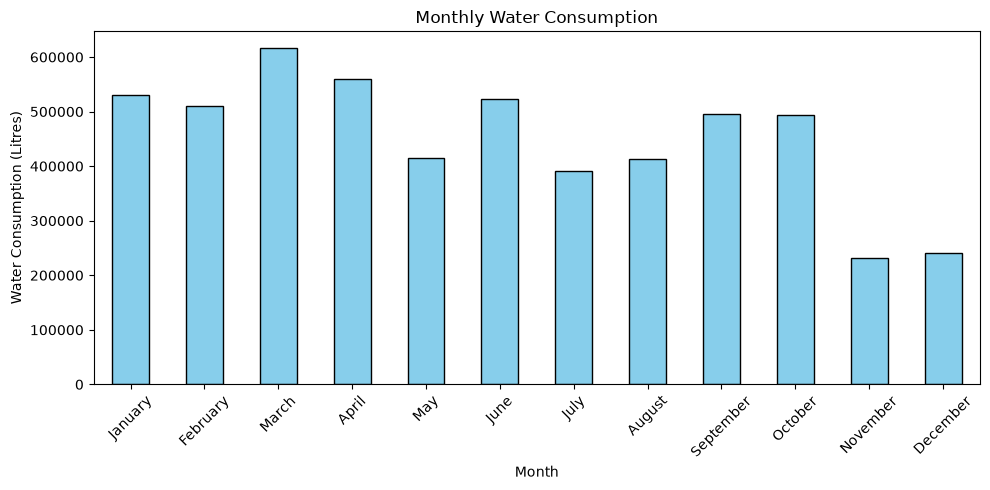

Monthly chart saved successfully!


In [41]:
# ==========================================
# TASK 14: MONTHLY WATER CONSUMPTION CHART
# ==========================================

import matplotlib.pyplot as plt

print("\n========== CREATING MONTHLY CHART ==========")

plt.figure(figsize=(10, 5))

monthly_totals.plot(
    kind="bar",
    color="skyblue",
    edgecolor="black"
)

plt.title("Monthly Water Consumption")
plt.xlabel("Month")
plt.ylabel("Water Consumption (Litres)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("outputs/monthly_consumption_chart.png")

plt.show()

print("Monthly chart saved successfully!")

In [42]:
%pip install matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


C:\Users\hp\AppData\Local\Temp\ipykernel_10084\1008553880.py:9: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  household_analysis.rename(


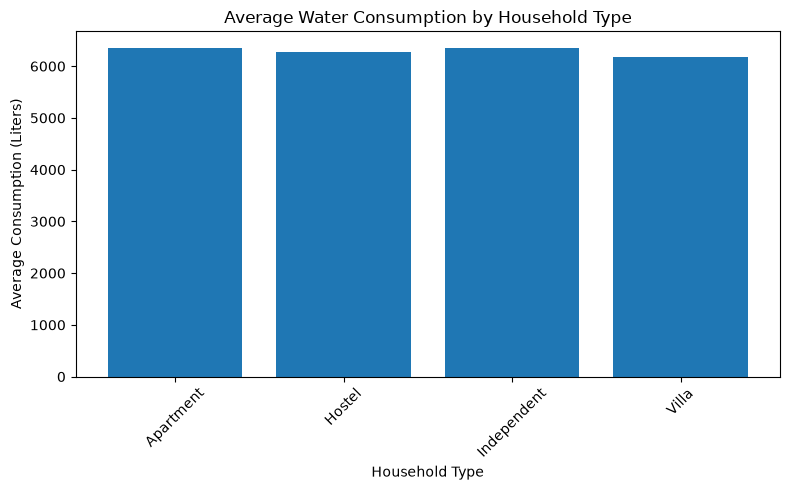

In [43]:
# ==========================================
# TASK 15: HOUSEHOLD TYPE CONSUMPTION CHART
# ==========================================

household_analysis = df.groupby(
    "Household_Type"
)["Water_Usage_Liters"].mean().reset_index()

household_analysis.rename(
    columns={"Water_Usage_Liters": "Average_Consumption"},
    inplace=True
)

plt.figure(figsize=(8, 5))

plt.bar(
    household_analysis["Household_Type"],
    household_analysis["Average_Consumption"]
)

plt.title("Average Water Consumption by Household Type")
plt.xlabel("Household Type")
plt.ylabel("Average Consumption (Liters)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("outputs/household_type_chart.png")
plt.show()

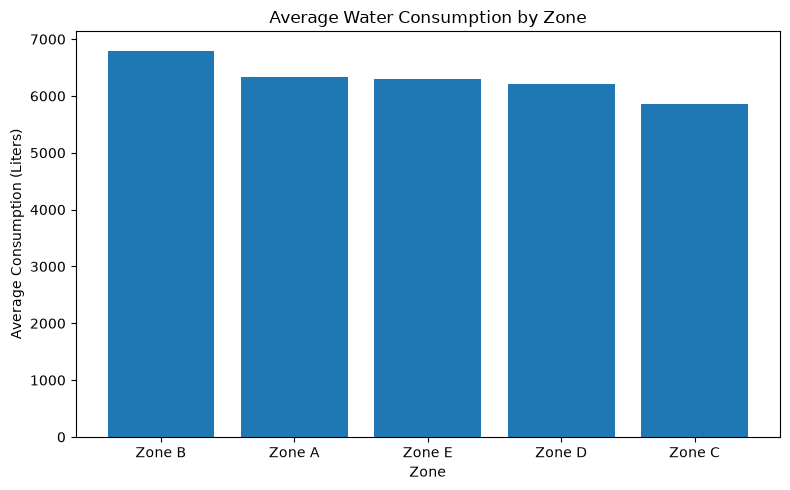

In [44]:
# ==========================================
# TASK 16: ZONE-WISE CONSUMPTION CHART
# ==========================================

plt.figure(figsize=(8, 5))

plt.bar(
    zone_analysis["Zone"],
    zone_analysis["Average_Consumption"]
)

plt.title("Average Water Consumption by Zone")
plt.xlabel("Zone")
plt.ylabel("Average Consumption (Liters)")
plt.tight_layout()

plt.savefig("outputs/zone_consumption_chart.png")
plt.show()